<a href="https://colab.research.google.com/github/MajedMMH/Student-Behaviour-CNN/blob/main/Student_Behaviour_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Behaviour Classification in the Classroom
### AI433 Deep Learning — Course Project

A CNN that looks at one student photo and says what the student is doing:
**hand-raising**, **reading** or **writing**.

The notebook follows the six phases of **CRISP-DM** (Cross-Industry Standard Process for Data Mining).
Each member owns one phase, in the code and in the report:

| # | Phase | Owner |
|---|---|---|
| 1 | Business Understanding | AS012345 |
| 2 | Data Understanding | MajedMMH |
| 3 | Data Preparation | Abdulaziz-505 |
| 4 | Modeling | ahmedkhosim-s |
| 5 | Evaluation | Tamim0700 |
| 6 | Deployment | Otarabishi |

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import PIL
import pathlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

tf.random.set_seed(42)

# 1. Business Understanding
Teachers may find it difficult to continuously monitor all students in a classroom. This project develops a CNN model that classifies student behaviour from classroom images into three classes: hand-raising, reading and writing. Other behaviours, such as sleeping, talking and using mobile phones, are left for future work.

# 2. Data Understanding

In [ ]:
dataset_url = "https://drive.usercontent.google.com/download?id=1Ax29bNB54fXodYJ1KIjSuHVR9_k1jRHP&export=download&confirm=t"
tf.keras.utils.get_file('student_behaviour.zip', origin=dataset_url, cache_dir='.', extract=True)

72719741/72719741 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


'./datasets/student_behaviour_extracted'

In [ ]:
data_dir = pathlib.Path('/content/datasets/student_behaviour_extracted/student_behaviour')
data_dir

PosixPath('/content/datasets/student_behaviour_extracted/student_behaviour')

In [ ]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

23429


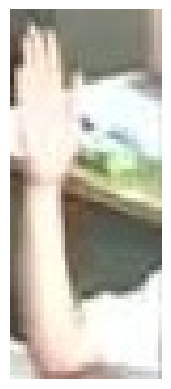

In [ ]:
hand_raising_images = list(data_dir.glob('hand-raising/*'))
plt.imshow(PIL.Image.open(hand_raising_images[0]))
plt.axis('off')
plt.show()

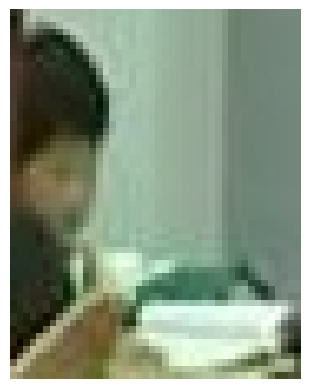

In [ ]:
reading_images = list(data_dir.glob('reading/*'))
plt.imshow(PIL.Image.open(reading_images[1]))
plt.axis('off')
plt.show()

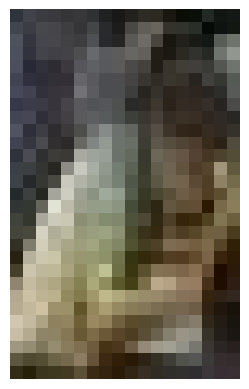

In [ ]:
writing_images = list(data_dir.glob('writing/*'))
plt.imshow(PIL.Image.open(writing_images[1]))
plt.axis('off')
plt.show()

In [ ]:
print(len(hand_raising_images), len(reading_images), len(writing_images))

10364 9573 3492


# 3. Data Preparation

In [ ]:
behaviour_images = {
    'hand-raising': hand_raising_images,
    'reading': reading_images,
    'writing': writing_images,
}

In [ ]:
behaviour_labels = {
    'hand-raising': 0,
    'reading': 1,
    'writing': 2,
}

In [ ]:
cv2.imread(str(hand_raising_images[0])).shape

(88, 36, 3)

In [ ]:
X, y = [], []

for behaviour, image_paths in behaviour_images.items():
    for image_path in image_paths:
        img = cv2.imread(str(image_path))
        X.append(cv2.resize(img, (64, 64)))
        y.append(behaviour_labels[behaviour])

In [ ]:
X = np.array(X)
y = np.array(y)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [ ]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

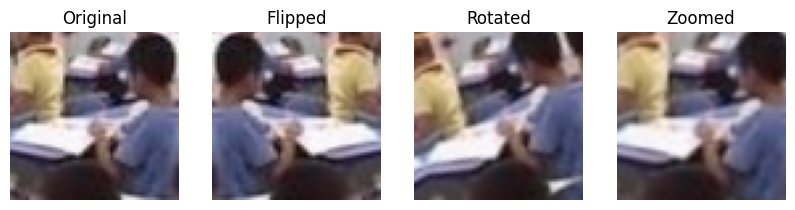

In [ ]:
flipped = layers.RandomFlip("horizontal", seed=3)(X_train[:1], training=True)
rotated = layers.RandomRotation(0.1, seed=7)(X_train[:1], training=True)
zoomed = layers.RandomZoom(0.1, seed=5)(X_train[:1], training=True)

images = [X_train[0], flipped[0], rotated[0], zoomed[0]]
titles = ['Original', 'Flipped', 'Rotated', 'Zoomed']
plt.figure(figsize=(10, 3))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(np.array(images[i]).astype('uint8')[:, :, ::-1])
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# 4. Modeling

### Build convolutional neural network and train it

In [ ]:
num_classes = 3

model = Sequential([
  layers.Input(shape=(64, 64, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 548,387 (2.09 MB)

 Trainable params: 548,387 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(X_train_scaled, y_train, epochs=30)

Epoch 1/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.6272 - loss: 0.8192
Epoch 2/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6900 - loss: 0.7034
Epoch 3/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7230 - loss: 0.6363
Epoch 4/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.7542 - loss: 0.5687
Epoch 5/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7912 - loss: 0.4929
Epoch 6/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8221 - loss: 0.4232
Epoch 7/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8525 - loss: 0.3604
Epoch 8/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8768 - loss: 0.3071
Epoch 9/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9000 - loss: 0.2535
Epoch 10/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9198 - loss: 0.2083
Epoch 11/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9335 - loss: 0.1764
Epoch 12/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/st

In [ ]:
model.evaluate(X_test_scaled, y_test)

147/147 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.7164 - loss: 2.2076


[2.207554817199707, 0.7163892388343811]

In [ ]:
predictions = model.predict(X_test_scaled)
predictions[0]

147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


array([9.999999e-01, 6.819994e-08, 4.848310e-08], dtype=float32)

In [ ]:
np.argmax(predictions[0])

np.int64(0)

In [ ]:
y_test[0]

np.int64(0)

### Improve test accuracy using data augmentation and a dropout layer

In [ ]:
model_aug = Sequential([
  layers.Input(shape=(64, 64, 3)),
  data_augmentation,
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Dropout(0.2),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

model_aug.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

model_aug.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 548,387 (2.09 MB)

 Trainable params: 548,387 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_aug = model_aug.fit(X_train_scaled, y_train, epochs=30)

Epoch 1/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.5823 - loss: 0.9026
Epoch 2/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.6341 - loss: 0.8214
Epoch 3/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6559 - loss: 0.7764
Epoch 4/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.6686 - loss: 0.7506
Epoch 5/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.6820 - loss: 0.7225
Epoch 6/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6870 - loss: 0.7094
Epoch 7/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6977 - loss: 0.6895
Epoch 8/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7032 - loss: 0.6794
Epoch 9/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7109 - loss: 0.6656
Epoch 10/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7152 - loss: 0.6506
Epoch 11/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7248 - loss: 0.6431
Epoch 12/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/st

In [ ]:
model_aug.evaluate(X_test_scaled, y_test)

147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7599 - loss: 0.5776


[0.5776473879814148, 0.7599231600761414]

### Compare the two models

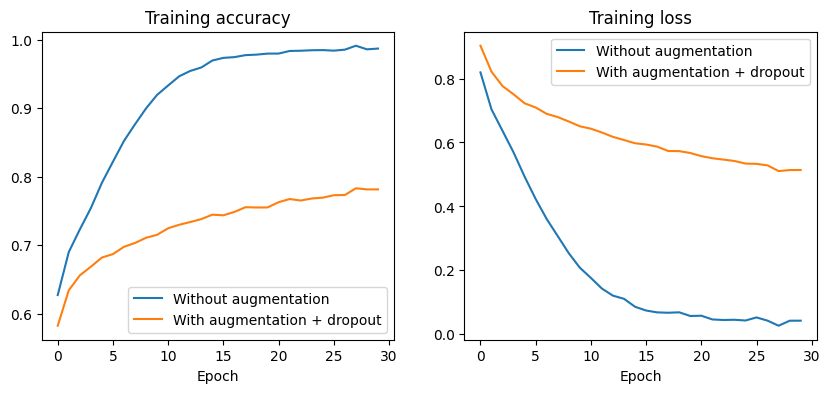

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Without augmentation')
plt.plot(history_aug.history['accuracy'], label='With augmentation + dropout')
plt.title('Training accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Without augmentation')
plt.plot(history_aug.history['loss'], label='With augmentation + dropout')
plt.title('Training loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [ ]:
_, train_acc = model.evaluate(X_train_scaled, y_train, verbose=0)
_, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
_, train_acc_aug = model_aug.evaluate(X_train_scaled, y_train, verbose=0)
_, test_acc_aug = model_aug.evaluate(X_test_scaled, y_test, verbose=0)

print(f"Model 1 (no augmentation):     train {train_acc:.2%}  test {test_acc:.2%}")
print(f"Model 2 (augmentation+dropout): train {train_acc_aug:.2%}  test {test_acc_aug:.2%}")

best_model = model_aug if test_acc_aug >= test_acc else model
print("Best model:", "Model 2" if best_model is model_aug else "Model 1")

Model 1 (no augmentation):     train 96.85%  test 71.64%
Model 2 (augmentation+dropout): train 81.58%  test 75.99%
Best model: Model 2


# 5. Evaluation

In [ ]:
best_model.evaluate(X_test_scaled, y_test)

147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7599 - loss: 0.5776


[0.5776473879814148, 0.7599231600761414]

In [ ]:
y_pred = best_model.predict(X_test_scaled)
y_pred[:5]

147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


array([[3.0842525e-01, 2.4654819e-01, 4.4502661e-01],
       [4.3193379e-01, 4.7243229e-01, 9.5633902e-02],
       [2.4581568e-01, 2.9696277e-01, 4.5722151e-01],
       [9.9645281e-01, 3.4368620e-03, 1.1034355e-04],
       [4.8253697e-01, 5.0436503e-01, 1.3097962e-02]], dtype=float32)

In [ ]:
y_classes = [np.argmax(element) for element in y_pred]
y_classes[:5]

[np.int64(2), np.int64(1), np.int64(2), np.int64(0), np.int64(1)]

In [ ]:
y_test[:5]

array([0, 1, 0, 0, 0])

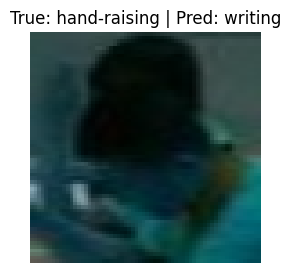

In [ ]:
classes = list(behaviour_labels.keys())

plt.figure(figsize=(3, 3))
plt.imshow(X_test_scaled[0])
plt.title(f"True: {classes[y_test[0]]} | Pred: {classes[y_classes[0]]}")
plt.axis('off')
plt.show()

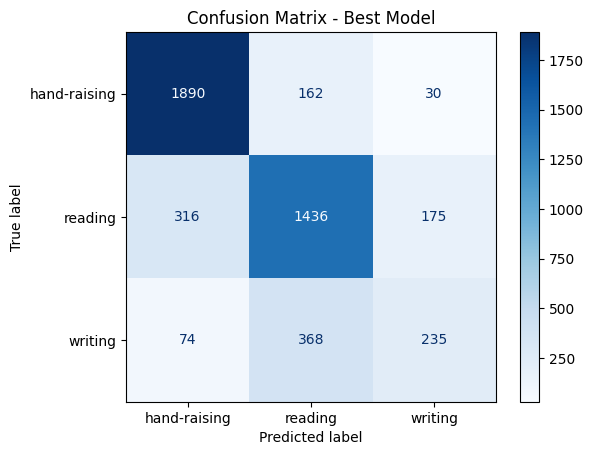

In [ ]:
cm = confusion_matrix(y_test, y_classes)

ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues')
plt.title('Confusion Matrix - Best Model')
plt.show()

In [ ]:
print("Classification Report (Best Model):\n", classification_report(y_test, y_classes, target_names=classes))

Classification Report (Best Model):
               precision    recall  f1-score   support

hand-raising       0.83      0.91      0.87      2082
     reading       0.73      0.75      0.74      1927
     writing       0.53      0.35      0.42       677

    accuracy                           0.76      4686
   macro avg       0.70      0.67      0.68      4686
weighted avg       0.75      0.76      0.75      4686



In [ ]:
y_pred_m1 = model.predict(X_test_scaled, verbose=0)
y_classes_m1 = np.argmax(y_pred_m1, axis=1)

y_pred_m2 = model_aug.predict(X_test_scaled, verbose=0)
y_classes_m2 = np.argmax(y_pred_m2, axis=1)

print("Model 1 (No Augmentation) Classification Report:\n", classification_report(y_test, y_classes_m1, target_names=classes))
print("Model 2 (Augmentation + Dropout) Classification Report:\n", classification_report(y_test, y_classes_m2, target_names=classes))

Model 1 (No Augmentation) Classification Report:
               precision    recall  f1-score   support

hand-raising       0.82      0.86      0.84      2082
     reading       0.69      0.68      0.69      1927
     writing       0.42      0.37      0.40       677

    accuracy                           0.72      4686
   macro avg       0.64      0.64      0.64      4686
weighted avg       0.71      0.72      0.71      4686

Model 2 (Augmentation + Dropout) Classification Report:
               precision    recall  f1-score   support

hand-raising       0.83      0.91      0.87      2082
     reading       0.73      0.75      0.74      1927
     writing       0.53      0.35      0.42       677

    accuracy                           0.76      4686
   macro avg       0.70      0.67      0.68      4686
weighted avg       0.75      0.76      0.75      4686



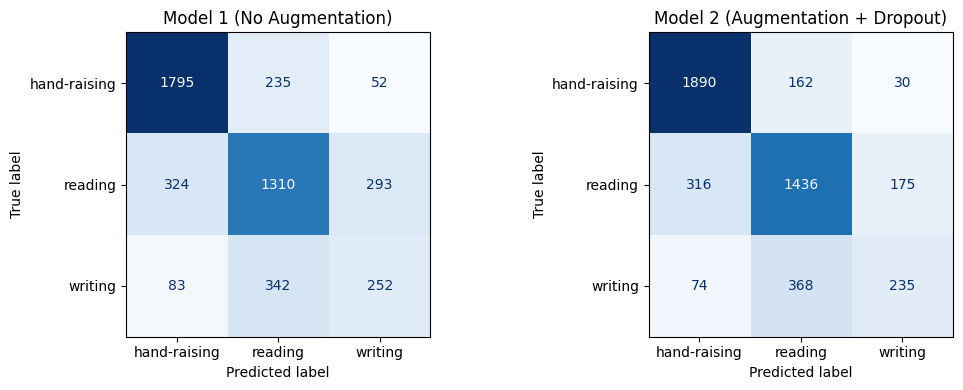

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_classes_m1), display_labels=classes).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Model 1 (No Augmentation)')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_classes_m2), display_labels=classes).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Model 2 (Augmentation + Dropout)')
plt.tight_layout()
plt.show()

Comparing model 1 results and model 2 results shows that Model 2 outperforms Model 1 across accuracy (0.75 vs 0.72), macro average F1-score (0.67 vs 0.64), and weighted average F1-score (0.74 vs 0.72). Hand-raising achieves the strongest F1-score (0.86), followed by reading (0.73, with recall improving from 0.72 to 0.77). For writing, Model 2 improves precision from 0.41 to 0.49, though recall decreases from 0.40 to 0.35, resulting in a similar F1-score (0.41 vs 0.40). Overall, Model 2 generalises better and is confirmed as the best model, though future work could address the class imbalance and the confusion between reading and writing.

# 6. Deployment
In this project, the model was not deployed to a real website or API. Instead, this section shows the main steps that any real deployment would follow: saving the trained model, loading it again, and using it to predict the behaviour of a new image. A web application or an API would run these same steps behind the scenes.

In [45]:
best_model.save('student_behaviour_model.keras')

deploy_model = keras.models.load_model('student_behaviour_model.keras')

_, reload_acc = deploy_model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Model saved and reloaded successfully | test accuracy: {reload_acc:.2%}")

Model saved and reloaded successfully | test accuracy: 76.42%


### Predictive System
Predict the behaviour for any new image with the same preprocessing pipeline used in training: read the image with `cv2`, resize it to 64×64, scale it by /255, then predict and print the class name with its probabilities.

In [46]:
def predict_student_behaviour(img_path, model=deploy_model):
    img = cv2.imread(str(img_path))                  # same loader used in training
    img = cv2.resize(img, (64, 64))                  # same input size used in training
    img_scaled = img / 255.0                         # same scaling used in training
    img_input = np.expand_dims(img_scaled, axis=0)

    probs = model.predict(img_input, verbose=0)[0]
    class_idx = int(np.argmax(probs))

    print(f"Predicted behaviour: {classes[class_idx]}")
    for name, p in zip(classes, probs):
        print(f"  {name:12s}: {p:.2%}")
    return classes[class_idx], probs

Predicted behaviour: hand-raising
  hand-raising: 99.51%
  reading     : 0.38%
  writing     : 0.10%
Predicted behaviour: hand-raising
  hand-raising: 65.97%
  reading     : 23.46%
  writing     : 10.57%
Predicted behaviour: writing
  hand-raising: 4.58%
  reading     : 41.59%
  writing     : 53.83%


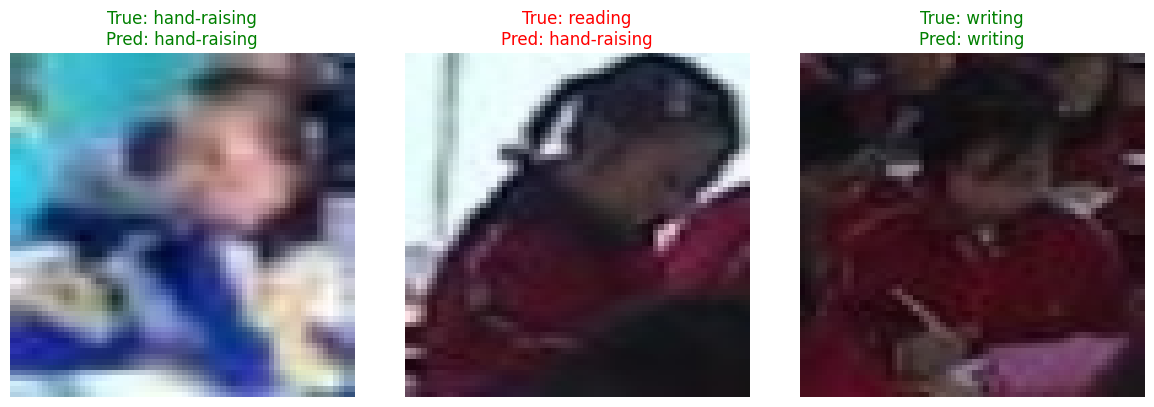

In [47]:
# Try the predictive system on one sample image per class
sample_images = {
    'hand-raising': hand_raising_images[200],
    'reading': reading_images[200],
    'writing': writing_images[200],
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (true_label, img_path) in zip(axes, sample_images.items()):
    predicted, probs = predict_student_behaviour(img_path)
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    ax.imshow(cv2.resize(img, (64, 64)))
    color = 'green' if predicted == true_label else 'red'
    ax.set_title(f"True: {true_label}\nPred: {predicted}", color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Testing the predictive system on unseen images
Test the deployed model on random images from the test set `X_test` (images the model never saw during training) and count how many predictions are correct.

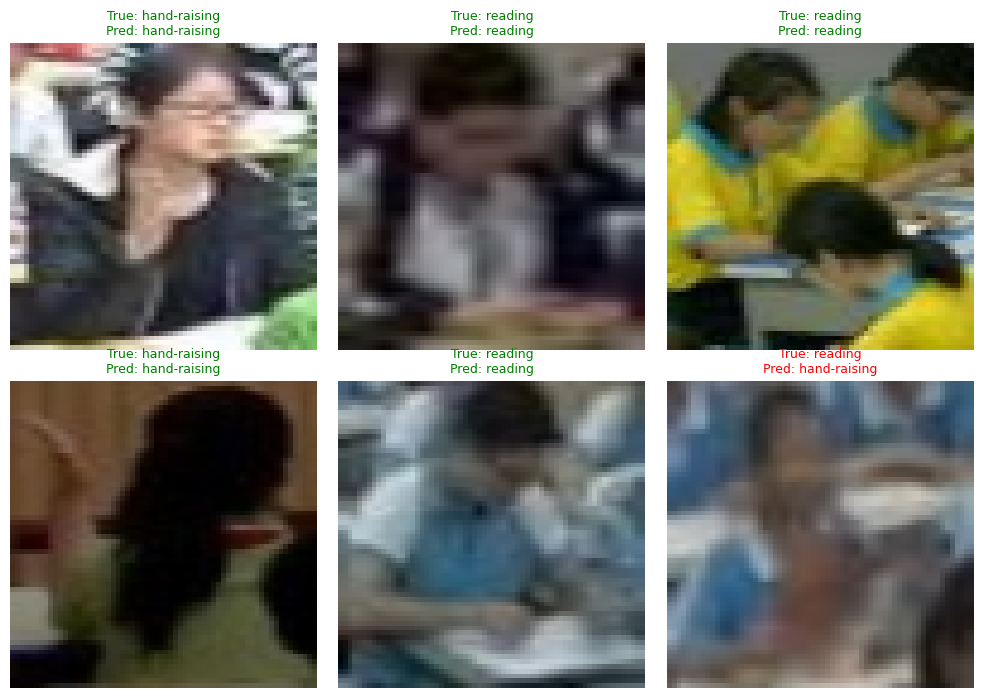

Correct predictions on unseen test images: 5/6


In [48]:
test_indices = np.random.default_rng(42).choice(len(X_test), size=6, replace=False)

correct = 0
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, idx in zip(axes.flat, test_indices):
    img = X_test[idx]
    probs = deploy_model.predict(np.expand_dims(img / 255.0, axis=0), verbose=0)[0]
    predicted = classes[int(np.argmax(probs))]
    true_label = classes[y_test[idx]]
    correct += (predicted == true_label)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    color = 'green' if predicted == true_label else 'red'
    ax.set_title(f"True: {true_label}\nPred: {predicted}", color=color, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()
print(f"Correct predictions on unseen test images: {correct}/{len(test_indices)}")

# References
1. SCB-dataset on GitHub: https://github.com/Whiffe/SCB-dataset
2. SCB-dataset-3 on Roboflow Universe: https://universe.roboflow.com/studentactivity/scb-dataset-3
3. Reference notebook, Flower classification with CNN and data augmentation (Sections 2–4): https://colab.research.google.com/drive/1VDc_TOCuG4eJ45Idv4aEYQDUQ2Yu7Rfp
4. Reference notebook, CIFAR-10 classification with CNN (Section 5): https://colab.research.google.com/drive/190WdgRLeIyUbzQ0Ir0mEEAWPggmSosBg
5. Reference notebook, Dogs vs Cats classification (Section 6): https://colab.research.google.com/drive/1ltb3NNJZvbMNHej17tDSdC-uYWI6izKF